# Week 4, session 1: equal width and equal frequency discretisation (in-class exercises): student version

**Computational AI · Dr Mabrouka Abuhmida · University of South Wales**

Today you turn continuous columns into bins, and you find out what that gains and what it costs. Every task uses the same ward dataset as week 3, and each one matches an exercise on the slides.

1. Equal width discretisation with `pd.cut`
2. Equal frequency discretisation with `pd.qcut`
3. Learning bin edges on training data, so test patients always get a bin

Work in pairs. Write short answers wherever you see **Your answer**.

**Submission:** when you finish, run all cells (Kernel > Restart and Run All) and upload this notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## Dataset instructions

- File: `ward_admissions.csv`, the same file as week 3. Put it in the same folder as this notebook (in Colab, upload it with the folder icon on the left).
- The data is **fictional** and built for teaching. Patterns were planted on purpose, so do not read them as clinical findings.
- Libraries: `pandas`, `numpy`, `matplotlib`, `scikit-learn`.
- Columns you need today: `age`, `heart_rate`, `resp_rate`, `length_of_stay` and the target `deteriorated` (1 = the patient deteriorated within 24 hours).

## Setup and data loading

Run this cell as it is. It repeats the week 3 clean-up: `heart_rate = 999` means "not recorded", so it becomes NaN.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

plt.rcParams["figure.figsize"] = [8, 4.5]

ward = pd.read_csv("ward_admissions.csv")
ward["heart_rate"] = ward["heart_rate"].replace(999, np.nan)
num_cols = ["age", "heart_rate", "resp_rate", "length_of_stay"]
print(ward.shape)
print(ward[num_cols].skew().round(2))
ward[num_cols].describe().round(1)

(1200, 11)
age               0.02
heart_rate        0.84
resp_rate         1.01
length_of_stay    6.21
dtype: float64


,age,heart_rate,resp_rate,length_of_stay
count,1200.0,1177.0,1200.0,1200.0
mean,66.3,86.5,17.6,6.7
std,13.7,15.8,3.0,8.7
min,22.0,32.0,10.0,0.6
25%,57.0,76.0,16.0,2.9
50%,66.0,86.0,18.0,4.7
75%,76.0,96.0,19.0,7.6
max,99.0,176.0,38.0,94.4


## Theory reminder: two unsupervised methods

- **Equal width** (`pd.cut(x, bins=k)`): every bin has the same width, (max − min) / k. Easy to explain, but on skewed data most rows land in one bin.
- **Equal frequency** (`pd.qcut(x, q=k)`): every bin has about the same number of rows. Edges are quantiles, so widths differ.
- `retbins=True` returns the edges as well as the bins. Keep them: you need them for test data.
- `value_counts(sort=False)` keeps the bins in order. `groupby(..., observed=True)` uses only the bins that exist.
- Binning throws detail away: every value in a bin becomes the same (Altman and Royston, 2006).

## Student Task 1: bins by hand (slide exercise 1)

**Goal:** build equal width and equal frequency bins on paper, then check them in pandas.

Ages: 20, 25, 30, 35, 40, 45, 50, 90

**Steps:**
1. Equal width, 3 bins: find the width and the edges.
2. Count the ages in each bin.
3. Equal frequency, 4 bins: count the ages in each bin.
4. Check both with `pd.cut` and `pd.qcut` in the cell below.

**Expected output:** equal width counts 5, 2 and 1; equal frequency counts 2, 2, 2 and 2.

**Reflection question:** which method lets the 90 year old decide the edges?

In [8]:
ages = pd.Series([20, 25, 30, 35, 40, 45, 50, 90])

# TODO: Complete this task
# Hint: pd.cut(ages, bins=3, retbins=True)
# Hint: pd.qcut(ages, q=4, retbins=True)
# Add your code here
ew, ew_edges = pd.cut(ages, bins=3, retbins=True)
ef, ef_edges = pd.qcut(ages, q=4, retbins=True)

print("Equal width edges:", ew_edges.round(1))
print(ew.value_counts(sort=False))
print("Equal frequency edges:", ef_edges)
print(ef.value_counts(sort=False))


Equal width edges: [19.9 43.3 66.7 90. ]
(19.93, 43.333]     5
(43.333, 66.667]    2
(66.667, 90.0]      1
Name: count, dtype: int64
Equal frequency edges: [20.   28.75 37.5  46.25 90.  ]
(19.999, 28.75]    2
(28.75, 37.5]      2
(37.5, 46.25]      2
(46.25, 90.0]      2
Name: count, dtype: int64


**Your answer:**

 `pd.cut` lets the 90 year old decide the adges, because the width is (maximum - minimum)/k so the 90 year old outlier stretches every bin `qcut` uses quantiles of the data so each bins keeps 2 people

## Student Task 2: age, two ways (slide exercise 2)

**Goal:** compare equal width and equal frequency on a symmetric column.

**Steps:**
1. Bin `age` with `pd.cut` and with `pd.qcut`, 5 bins each, `retbins=True`. Store them as `age_ew` and `age_ef`.
2. Print the edges and the counts for both.
3. Compute the deterioration rate per bin for both.
4. Plot the two rate charts side by side (visualisation cell below).

**Expected output:** equal width counts 20, 172, 494, 383, 131. Equal frequency edges 22, 55, 63, 69, 78, 99.

**Reflection question:** which version would you show a ward manager, and why?

In [9]:
ward["age_ew"], age_ew_edges = pd.cut(ward["age"], bins=5, retbins=True)
# TODO: Complete this task
# TODO: age_ef with pd.qcut(..., q=5, retbins=True)
# TODO: print edges and value_counts(sort=False) for both
# TODO: ward.groupby("age_ew", observed=True)["deteriorated"].agg(["count", "mean"])
# Add your code here
ward["age_ew"], age_ew_edges = pd.cut(ward["age"], bins=5, retbins=True)
ward["age_ef"], age_ef_edges = pd.qcut(ward["age"], q=5, retbins=True)

print("EW edges:", age_ew_edges.round(1))
print(ward["age_ew"].value_counts(sort=False))
print("EF edges:", age_ef_edges)
print(ward["age_ef"].value_counts(sort=False))

ew_rates = ward.groupby("age_ew", observed=True)["deteriorated"].agg(["count", "mean"])
ef_rates = ward.groupby("age_ef", observed=True)["deteriorated"].agg(["count", "mean"])
print(ew_rates)
print(ef_rates)

EW edges: [21.9 37.4 52.8 68.2 83.6 99. ]
age_ew
(21.923, 37.4]     20
(37.4, 52.8]      172
(52.8, 68.2]      494
(68.2, 83.6]      383
(83.6, 99.0]      131
Name: count, dtype: int64
EF edges: [22. 55. 63. 69. 78. 99.]
age_ef
(21.999, 55.0]    265
(55.0, 63.0]      243
(63.0, 69.0]      220
(69.0, 78.0]      245
(78.0, 99.0]      227
Name: count, dtype: int64
                count      mean
age_ew                         
(21.923, 37.4]     20  0.200000
(37.4, 52.8]      172  0.087209
(52.8, 68.2]      494  0.111336
(68.2, 83.6]      383  0.195822
(83.6, 99.0]      131  0.320611
                count      mean
age_ef                         
(21.999, 55.0]    265  0.098113
(55.0, 63.0]      243  0.098765
(63.0, 69.0]      220  0.131818
(69.0, 78.0]      245  0.208163
(78.0, 99.0]      227  0.268722


### Visualisation: risk by age bin

Two bar charts, one per method, sharing the same y axis. Both should show risk rising with age. Look at the first bar of the equal width chart: how many patients is it based on?

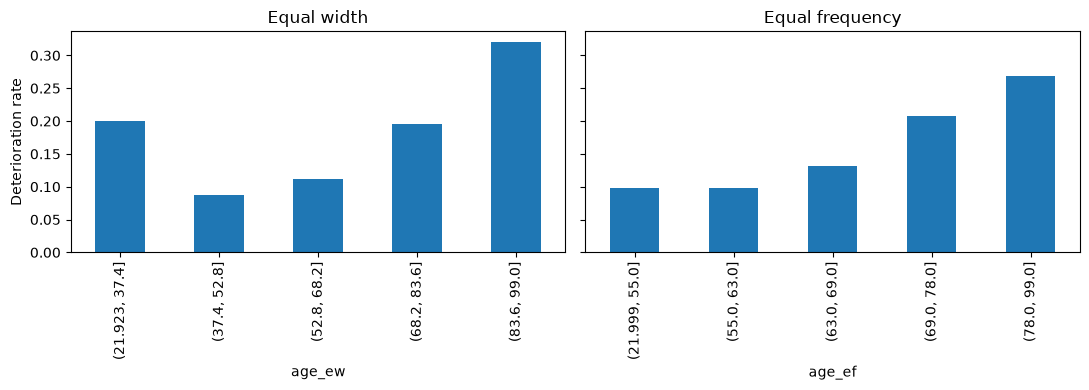

In [10]:
# TODO: Complete this task
# Hint: fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
# Hint: ward.groupby("age_ew", observed=True)["deteriorated"].mean().plot(kind="bar", ax=axes[0])
# Add your code here
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ew_rates["mean"].plot(kind="bar", ax=axes[0], title="Equal width")
ef_rates["mean"].plot(kind="bar", ax=axes[1], title="Equal frequency")
axes[0].set_ylabel("Deterioration rate")
plt.tight_layout()
plt.show()

**Your answer:**

I'd show the ward manager the equal frequency graph. The first equal width bar is based on just 20 patients while each equal frequency bar has about 240 patients, since each bar has a similar number of patients it easily explains the trend as opposed to the noisy equal width bar

## Student Task 3: heart rate and unseen patients (slide exercise 3)

**Goal:** learn bin edges on training data and apply them safely to test data.

**Steps:**
1. Split `ward` with `test_size=0.25, random_state=42`.
2. Fill `heart_rate` in both sets with the **training** median.
3. Learn 6 equal frequency edges on the training heart rates (`pd.qcut(..., retbins=True)`).
4. Apply the edges to the test set with `pd.cut`. Count how many test rows become NaN.
5. Now bin three new patients, `new = pd.Series([30, 85, 190])`, with the same edges. Count the NaN.
6. Replace the first and last edge with `-np.inf` and `np.inf`, and bin the new patients again.

**Expected output:** this test set happens to sit inside the training range (0 NaN), but the new patients at 30 and 190 bpm become NaN with closed ends. With open ends, nobody is lost.

**Reflection question:** what would happen to a new patient at 190 bpm with the closed edges?

In [11]:
train, test = train_test_split(ward, test_size=0.25, random_state=42)
train, test = train.copy(), test.copy()
# TODO: Complete this task
# Step 2: hr_median = train["heart_rate"].median(), then fillna on both
hr_median = train["heart_rate"].median()
train["heart_rate"] = train["heart_rate"].fillna(hr_median)
test["heart_rate"] = test["heart_rate"].fillna(hr_median)

# Step 3: _, hr_edges = pd.qcut(train["heart_rate"], q=6, retbins=True)
_, hr_edges = pd.qcut(train["heart_rate"], q=6, retbins=True)
print("Edges:", hr_edges)

# Step 4: pd.cut(test["heart_rate"], bins=hr_edges).isnull().sum()
print("Test NaN:", pd.cut(test["heart_rate"], bins=hr_edges).isnull().sum())

# Step 5: new = pd.Series([30, 85, 190]); pd.cut(new, bins=hr_edges)
new = pd.Series([30, 85, 190])
print(pd.cut(new, bins=hr_edges))
print("New NaN (closed):", pd.cut(new, bins=hr_edges).isnull().sum())

# Step 6: open the ends and repeat
open_edges = hr_edges.copy()
open_edges[0], open_edges[-1] = -np.inf, np.inf
print(pd.cut(new, bins=open_edges))
print("New NaN (open):", pd.cut(new, bins=open_edges).isnull().sum())

Edges: [ 32.  72.  80.  86.  92. 100. 176.]
Test NaN: 0
0             NaN
1    (80.0, 86.0]
2             NaN
dtype: category
Categories (6, interval[float64, right]): [(32.0, 72.0] < (72.0, 80.0] < (80.0, 86.0] < (86.0, 92.0] < (92.0, 100.0] < (100.0, 176.0]]
New NaN (closed): 2
0    (-inf, 72.0]
1    (80.0, 86.0]
2    (100.0, inf]
dtype: category
Categories (6, interval[float64, right]): [(-inf, 72.0] < (72.0, 80.0] < (80.0, 86.0] < (86.0, 92.0] < (92.0, 100.0] < (100.0, inf]]
New NaN (open): 0


**Your answer:**

A patient at 190 bpm falls outside the training range so `pd.cut` gives them NaN. It silently gets no bin and the model would treat them as missing even thought they are probably the sickest patient while using open ends puts them in the top bin

## Student Task 4: choose the method (slide exercise 4)

For each column, choose equal width, equal frequency, or no binning at all, and say what you would lose.

- (a) Household income: very skewed, used in a credit model
- (b) Exam marks, 0 to 100, turned into grade bands for students
- (c) Days between hospital visits: most under 30, a few over 1,000
- (d) Body temperature: roughly symmetric, tight range

**Your answer:**

(a) Household income: equal frequency. Income is very skewed, so equal width would put almost everyone in the first bin. Equal frequency gives each bin enough people to be useful in a credit model. You lose the difference between high and very high earners, since everyone in the top bin is treated the same.

(b) Exam marks: equal width. The marks are bounded (0 to 100) and the grade bands are meant to be fixed, meaningful ranges such as 10 points each. Equal frequency would make the band edges shift from year to year, which isn’t fair to students. You lose the difference within a band, for example a 60 and a 69 are treated as the same.

(c) Days between hospital visits: equal frequency. A few values over 1,000 would decide the edges of equal width bins and squash nearly everyone into one bin. Equal frequency keeps the bins balanced. You lose the gap between very long waits, for example 1,000 and 3,000 days end up in the same top bin.

(d) Body temperature: equal width. The data is roughly symmetric with a tight range, so equal width bins will already be well filled, and their edges are easy to read and explain. You lose precision near clinical cut-offs, such as 38°C, if a bin edge doesn’t line up with them.

## Reflection

In three or four sentences: when would you choose equal width over equal frequency? Use one output from this notebook as evidence.

**Your answer:**

I would choose equal width when the data is roughly symmetric and I need round and easy to explain edges. The age column shows both sides of this. Equal width gave counts of 20, 172, 494, 383 and 131, so the sparse end bins gave unreliable risk estimates, such as the 20% rate from only 20 patients. Equal frequency avoided that by giving each bin 220 to 265 patients. So equal width suits evenly spread data where clear boundaries matter more, and equal frequency suits data with sparse tails or outliers where each bin needs enough patients to be trustworthy.

---

**Submission:** when you finish, run all cells (Kernel > Restart and Run All) and upload this notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## References

- Altman, D.G. and Royston, P. (2006) 'The cost of dichotomising continuous variables', *BMJ*, 332(7549), p. 1080.
- pandas development team (2024) *pandas.cut* and *pandas.qcut*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.cut.html